## 0. Моделирование запуска AES-128
### Подключение unicorn, emusca и генерация трасс

In [20]:
#%pip install gmpy2 intervaltree lief

In [21]:
import sys, os, binascii as ba
sys.path.insert(0, "emusca")

# Скомпилированная программа AES, которую emusca запускает внутри unicorn:
ELF     = "emusca/build/aes-sbox-dec-test.elf"

KEY     = ba.unhexlify("00112233445566778899aabbccddeeff")
IV      = b"\x00" * 16
N       = 500          # количество трасс
PREFIX  = "traces"    

In [22]:
from trace_api import TraceGenerator

gen = TraceGenerator(ELF)
cts = [os.urandom(16) for _ in range(N)]       # генерация случайных шифртекстов
results = gen.generate_traces(KEY, IV, cts)
gen.write_daredevil(KEY, cts, results, prefix=PREFIX)

print(f"ключ:     {ba.hexlify(KEY).decode()}")
print(f"трассы:   {N}")
print(f"семплы:   {len(results[0].hd_trace)}")
print(f"файлы:    {PREFIX}_in.bin, {PREFIX}_out.bin, {PREFIX}_trace.bin, {PREFIX}_daredevil.cfg")

ModuleNotFoundError: No module named 'trace_api'

# Реализация атаки на шифр AES

## 1. Константы

Загружаются таблицы, необходимые для моделирования внутренних операций AES:

- **Таблица подстановки (S-box)** — 256-байтовая таблица, задающая нелинейное преобразование SubBytes в AES.

- **Обратная таблица подстановки (Inverted S-box)** используется в InvSubBytes при дешифровании.

- **Раундовые константы (RCON)** предотвращают совпадение раундовых подключей.

- **Таблица весов Хэмминга (HW)** хранит веса для значений 0-255.

In [23]:
import numpy as np
import re
from pathlib import Path
import matplotlib.pyplot as plt

# S-box для AES 
SBOX = np.array([
    0x63,0x7C,0x77,0x7B,0xF2,0x6B,0x6F,0xC5,0x30,0x01,0x67,0x2B,0xFE,0xD7,0xAB,0x76,
    0xCA,0x82,0xC9,0x7D,0xFA,0x59,0x47,0xF0,0xAD,0xD4,0xA2,0xAF,0x9C,0xA4,0x72,0xC0,
    0xB7,0xFD,0x93,0x26,0x36,0x3F,0xF7,0xCC,0x34,0xA5,0xE5,0xF1,0x71,0xD8,0x31,0x15,
    0x04,0xC7,0x23,0xC3,0x18,0x96,0x05,0x9A,0x07,0x12,0x80,0xE2,0xEB,0x27,0xB2,0x75,
    0x09,0x83,0x2C,0x1A,0x1B,0x6E,0x5A,0xA0,0x52,0x3B,0xD6,0xB3,0x29,0xE3,0x2F,0x84,
    0x53,0xD1,0x00,0xED,0x20,0xFC,0xB1,0x5B,0x6A,0xCB,0xBE,0x39,0x4A,0x4C,0x58,0xCF,
    0xD0,0xEF,0xAA,0xFB,0x43,0x4D,0x33,0x85,0x45,0xF9,0x02,0x7F,0x50,0x3C,0x9F,0xA8,
    0x51,0xA3,0x40,0x8F,0x92,0x9D,0x38,0xF5,0xBC,0xB6,0xDA,0x21,0x10,0xFF,0xF3,0xD2,
    0xCD,0x0C,0x13,0xEC,0x5F,0x97,0x44,0x17,0xC4,0xA7,0x7E,0x3D,0x64,0x5D,0x19,0x73,
    0x60,0x81,0x4F,0xDC,0x22,0x2A,0x90,0x88,0x46,0xEE,0xB8,0x14,0xDE,0x5E,0x0B,0xDB,
    0xE0,0x32,0x3A,0x0A,0x49,0x06,0x24,0x5C,0xC2,0xD3,0xAC,0x62,0x91,0x95,0xE4,0x79,
    0xE7,0xC8,0x37,0x6D,0x8D,0xD5,0x4E,0xA9,0x6C,0x56,0xF4,0xEA,0x65,0x7A,0xAE,0x08,
    0xBA,0x78,0x25,0x2E,0x1C,0xA6,0xB4,0xC6,0xE8,0xDD,0x74,0x1F,0x4B,0xBD,0x8B,0x8A,
    0x70,0x3E,0xB5,0x66,0x48,0x03,0xF6,0x0E,0x61,0x35,0x57,0xB9,0x86,0xC1,0x1D,0x9E,
    0xE1,0xF8,0x98,0x11,0x69,0xD9,0x8E,0x94,0x9B,0x1E,0x87,0xE9,0xCE,0x55,0x28,0xDF,
    0x8C,0xA1,0x89,0x0D,0xBF,0xE6,0x42,0x68,0x41,0x99,0x2D,0x0F,0xB0,0x54,0xBB,0x16,
], dtype=np.uint8)

# Обратная функция к S-box
INV_SBOX = np.array([
    0x52,0x09,0x6A,0xD5,0x30,0x36,0xA5,0x38,0xBF,0x40,0xA3,0x9E,0x81,0xF3,0xD7,0xFB,
    0x7C,0xE3,0x39,0x82,0x9B,0x2F,0xFF,0x87,0x34,0x8E,0x43,0x44,0xC4,0xDE,0xE9,0xCB,
    0x54,0x7B,0x94,0x32,0xA6,0xC2,0x23,0x3D,0xEE,0x4C,0x95,0x0B,0x42,0xFA,0xC3,0x4E,
    0x08,0x2E,0xA1,0x66,0x28,0xD9,0x24,0xB2,0x76,0x5B,0xA2,0x49,0x6D,0x8B,0xD1,0x25,
    0x72,0xF8,0xF6,0x64,0x86,0x68,0x98,0x16,0xD4,0xA4,0x5C,0xCC,0x5D,0x65,0xB6,0x92,
    0x6C,0x70,0x48,0x50,0xFD,0xED,0xB9,0xDA,0x5E,0x15,0x46,0x57,0xA7,0x8D,0x9D,0x84,
    0x90,0xD8,0xAB,0x00,0x8C,0xBC,0xD3,0x0A,0xF7,0xE4,0x58,0x05,0xB8,0xB3,0x45,0x06,
    0xD0,0x2C,0x1E,0x8F,0xCA,0x3F,0x0F,0x02,0xC1,0xAF,0xBD,0x03,0x01,0x13,0x8A,0x6B,
    0x3A,0x91,0x11,0x41,0x4F,0x67,0xDC,0xEA,0x97,0xF2,0xCF,0xCE,0xF0,0xB4,0xE6,0x73,
    0x96,0xAC,0x74,0x22,0xE7,0xAD,0x35,0x85,0xE2,0xF9,0x37,0xE8,0x1C,0x75,0xDF,0x6E,
    0x47,0xF1,0x1A,0x71,0x1D,0x29,0xC5,0x89,0x6F,0xB7,0x62,0x0E,0xAA,0x18,0xBE,0x1B,
    0xFC,0x56,0x3E,0x4B,0xC6,0xD2,0x79,0x20,0x9A,0xDB,0xC0,0xFE,0x78,0xCD,0x5A,0xF4,
    0x1F,0xDD,0xA8,0x33,0x88,0x07,0xC7,0x31,0xB1,0x12,0x10,0x59,0x27,0x80,0xEC,0x5F,
    0x60,0x51,0x7F,0xA9,0x19,0xB5,0x4A,0x0D,0x2D,0xE5,0x7A,0x9F,0x93,0xC9,0x9C,0xEF,
    0xA0,0xE0,0x3B,0x4D,0xAE,0x2A,0xF5,0xB0,0xC8,0xEB,0xBB,0x3C,0x83,0x53,0x99,0x61,
    0x17,0x2B,0x04,0x7E,0xBA,0x77,0xD6,0x26,0xE1,0x69,0x14,0x63,0x55,0x21,0x0C,0x7D,
], dtype=np.uint8)

# Раундовые константы
RCON = np.array([
    0x00,0x01,0x02,0x04,0x08,0x10,0x20,0x40,
    0x80,0x1B,0x36,0x6C,0xD8,0xAB,0x4D,0x9A,
    0x2F,0x5E,0xBC,0x63,0xC6,0x97,0x35,0x6A,
    0xD4,0xB3,0x7D,0xFA,0xEF,0xC5,0x91,0x39,
], dtype=np.uint8)

# Таблица весов Хэмминга
HW = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

print('Константы загружены.')
print(f'  SBOX[0x00]     = 0x{SBOX[0]:02X}  (ожидается 0x63)')
print(f'  INV_SBOX[0x63] = 0x{INV_SBOX[0x63]:02X}  (ожидается 0x00)')
print(f'  HW[0xFF]       = {HW[0xFF]}  (ожидается 8)')

Константы загружены.
  SBOX[0x00]     = 0x63  (ожидается 0x63)
  INV_SBOX[0x63] = 0x00  (ожидается 0x00)
  HW[0xFF]       = 8  (ожидается 8)


## 2. Генерация подключей

**Forward key schedule** - алгоритм генерации 11 раундовых подключей на основе 128-битного мастер-ключа (каждый раундовый подключ также имеет длину 128 бит). Необходим для верификации результата атаки.

**Backward key schedule** - алгоритм восстановления мастер-ключа из подключа последнего раунда. Это финальный шаг атаки. 

In [24]:
def forward_key_schedule(key: bytes, n_rounds: int = 10) -> list:
    rk = list(key)
    for i in range(4, 4 * (n_rounds + 1)):
        a0, a1, a2, a3 = rk[(i-1)*4 : i*4]
        if i % 4 == 0:
            a0, a1, a2, a3 = int(SBOX[a1]), int(SBOX[a2]), int(SBOX[a3]), int(SBOX[a0])
            a0 ^= int(RCON[i // 4])
        b0, b1, b2, b3 = rk[(i-4)*4 : (i-3)*4]
        rk.extend([a0^b0, a1^b1, a2^b2, a3^b3])
    return rk


def backward_key_schedule(last_round_key: bytes, n_rounds: int = 10) -> list:
    rk = list(last_round_key)
    for i in range(n_rounds, 0, -1):
        b12 = rk[12]^rk[8];  b13 = rk[13]^rk[9]
        b14 = rk[14]^rk[10]; b15 = rk[15]^rk[11]
        b8  = rk[8] ^rk[4];  b9  = rk[9] ^rk[5]
        b10 = rk[10]^rk[6];  b11 = rk[11]^rk[7]
        b4  = rk[4] ^rk[0];  b5  = rk[5] ^rk[1]
        b6  = rk[6] ^rk[2];  b7  = rk[7] ^rk[3]
        a0 = int(SBOX[b13]) ^ int(RCON[i])
        a1 = int(SBOX[b14])
        a2 = int(SBOX[b15])
        a3 = int(SBOX[b12])
        b0 = a0^rk[0]; b1 = a1^rk[1]
        b2 = a2^rk[2]; b3 = a3^rk[3]
        rk = [b0,b1,b2,b3, b4,b5,b6,b7, b8,b9,b10,b11, b12,b13,b14,b15] + rk
    return rk


def verify_key(rk10: bytes, known_key: bytes) -> bool:
    return bytes(backward_key_schedule(rk10)[:16]) == known_key


# Самопроверка на тестовом векторе
_k  = bytes.fromhex('2b7e151628aed2a6abf7158809cf4f3c')
_rk = forward_key_schedule(_k)
# forward -> backward должно вернуть исходный ключ
_rk10 = bytes(_rk[160:176])
assert bytes(backward_key_schedule(_rk10)[:16]) == _k, 'Ошибка: ключи не совпадают!'
print(f'Key schedule: OK  (rk10 = {_rk10.hex()})')

Key schedule: OK  (rk10 = d014f9a8c9ee2589e13f0cc8b6630ca6)


### 3. Загрузка трасс из бинарных файлов

Трассы хранятся в формате Daredevil — простом бинарном формате. Данные разложены по отдельным файлам: шифртексты (in.bin), открытые тексты (out.bin) и сами трассы (trace.bin) записаны как плоские массивы байт без заголовков, а конфигурационный файл (daredevil.cfg) описывает их структуру. 

Такой формат удобен тем, что файлы загружаются как массивы NumPy одной строкой через np.frombuffer.

In [25]:
# 1. Чтение конфигурации 

def parse_daredevil_cfg(path: Path) -> dict:
    """Парсит .cfg-файл Daredevil: строки вида 'ключ = значение'."""
    params = {}
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('#') or line.startswith('['):
            continue
        m = re.match(r'(\w+)\s*=\s*(.+)', line)
        if m:
            params[m.group(1)] = m.group(2).strip()
    return params


cfg_path = Path(f'{PREFIX}_daredevil.cfg')

if cfg_path.exists():
    cfg = parse_daredevil_cfg(cfg_path)
else:
    print(f'Файл {cfg_path} не найден - используем параметры по умолчанию.')
    cfg = {}

# 2. Параметры трасс

TRACE_DTYPE = np.dtype(cfg.get('dtype', 'int32'))       # emusca пишет hd_trace как int32
N_TRACES    = int(cfg.get('number_of_traces', 500))
N_SAMPLES   = int(cfg.get('number_of_samples', 13643))

print(f'\nОжидаем: {N_TRACES} трасс × {N_SAMPLES} семплов, dtype={TRACE_DTYPE}')

# 3. Загрузка бинарных файлов в массивы NumPy

def load_bin(name: str, dtype, shape):
    raw = Path(f'{PREFIX}_{name}.bin').read_bytes()
    return np.frombuffer(raw, dtype=dtype).reshape(shape)

cts    = load_bin('in',    np.uint8,    (N_TRACES, 16))
pts    = load_bin('out',   np.uint8,    (N_TRACES, 16))
traces = load_bin('trace', TRACE_DTYPE, (N_TRACES, N_SAMPLES)).astype(np.float64)

# Вывод для проверки

print(f'\nЗагружено:')
print(f'  cts    {cts.shape}  {cts.dtype}')
print(f'  pts    {pts.shape}  {pts.dtype}')
print(f'  traces {traces.shape}  {traces.dtype}')

print(f'\nПервый шифртекст:  {ba.hexlify(cts[0]).decode()}')
print(f'Первый откр.текст: {ba.hexlify(pts[0]).decode()}')
print(f'Трасса[0]: min={traces[0].min():.1f}  max={traces[0].max():.1f}  mean={traces[0].mean():.2f}')


Ожидаем: 500 трасс × 13643 семплов, dtype=int32

Загружено:
  cts    (500, 16)  uint8
  pts    (500, 16)  uint8
  traces (500, 13643)  float64

Первый шифртекст:  e0a07dc9eb92ae25164efddfa6be4383
Первый откр.текст: e245215635eec09bc69e1c618b7a404a
Трасса[0]: min=1065353216.0  max=1114374144.0  mean=1083948012.41


### Визуализация

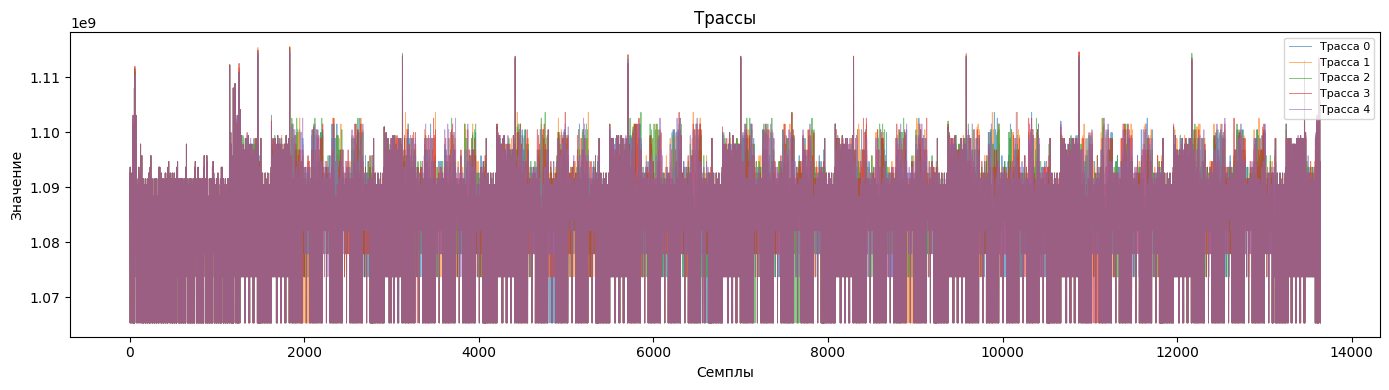

In [26]:
fig, ax = plt.subplots(figsize=(14, 4))
for i in range(min(5, N_TRACES)):
    ax.plot(traces[i], alpha=0.6, linewidth=0.7, label=f'Трасса {i}')
ax.set_title('Трассы')
ax.set_xlabel('Семплы')
ax.set_ylabel('Значение')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

Было выполнено дешифрование 500 шифртекстов с одним и тем же ключом. В AES-128 десять раундов, соответствующие 10 пиков энергопотребления легко увидеть на графике. 

## 4. DPA атака на последний раунд

In [27]:
# Вычисление подключа последнего раунда (rk10): 

_all_rk    = forward_key_schedule(KEY)
KNOWN_RK10 = bytes(_all_rk[160:176])

print(f'Известный ключ:  {KEY.hex()}')
print(f'Ожидаемый rk10:  {KNOWN_RK10.hex()}')

assert verify_key(KNOWN_RK10, KEY), 'backward_key_schedule broken!'
print('verify_key: OK')

Известный ключ:  00112233445566778899aabbccddeeff
Ожидаемый rk10:  36d024461d84b8375fc0f9c04cbab6bb
verify_key: OK


In [28]:
def dpa_attack(traces, cts, target_bit=0):
    
    """
    DPA атака на последний раунд AES-128.

    Для каждого из 16 байт раундового ключа rk10 перебирает все 256 гипотез,
    вычисляет гипотетический output InvSubBytes, разбивает трассы на две группы
    по значению целевого бита и выбирает гипотезу с максимальной разностью
    средних (Difference of Means).

    Параметры
    ---------
    traces : np.ndarray, shape (N, S)
        Матрица трасс энергопотребления (N трасс по S отсчётов).
    cts : np.ndarray, shape (N, 16), dtype uint8
        Шифртексты, соответствующие трассам.
    target_bit : int, default 0
        Номер бита (0-7) промежуточного значения, по которому
        трассы разбиваются на группы.
        
    Возвращает
    ----------
    recovered : list[int]
        16 восстановленных байт раундового ключа rk10.
    best_deltas : np.ndarray, shape (16, 256)
        Максимум DoM по всем семплам для каждого байта и каждой гипотезы.
    dom_traces : np.ndarray, shape (16, 256, S)
        Графики DoM для каждого байта и каждой гипотезы.
    """
    
    N, S = traces.shape
    guesses = np.arange(256, dtype=np.uint8)
    recovered   = []
    best_deltas = np.zeros((16, 256))
    dom_traces  = np.zeros((16, 256, S))

    for j in range(16):
        ct_j = cts[:, j] 

        # Вычисление промежуточных значений
        sbox_out = INV_SBOX[ct_j[None, :] ^ guesses[:, None]]

        # Гипотетический бит
        hyp_bit = (sbox_out >> target_bit) & 1

        # Разбиение трасс на группы
        mask1 = (hyp_bit == 1)                          
        mask0 = ~mask1
        count1 = mask1.sum(axis=1, keepdims=True).clip(1) 
        count0 = mask0.sum(axis=1, keepdims=True).clip(1)

        # Вычисление разности средних
        sum1 = mask1.astype(np.float64) @ traces
        sum0 = mask0.astype(np.float64) @ traces

        dom = np.abs(sum1 / count1 - sum0 / count0)  
        
        # Выбор лучшей гипотезы
        dom_traces[j]  = dom
        best_deltas[j] = dom.max(axis=1)
        recovered.append(int(best_deltas[j].argmax()))

    return recovered, best_deltas, dom_traces


print('Запускаем DPA, бит 0...')
recovered_dpa, deltas_dpa, dom_traces = dpa_attack(traces, cts, target_bit=0)
rk10_dpa = bytes(recovered_dpa)

print(f'\nВосстановленный rk10: {rk10_dpa.hex()}')
print(f'Ожидаемый       rk10: {KNOWN_RK10.hex()}')
print(f'Совпало байт: {sum(a==b for a,b in zip(rk10_dpa, KNOWN_RK10))}/16')

if verify_key(rk10_dpa, KEY):
    print(f'\n+++ Ключ ВЕРНЫЙ: {bytes(backward_key_schedule(rk10_dpa)[:16]).hex()}')
else:
    print('\n--- Неверно. Пробуем остальные биты...')
    for bit in range(1, 8):
        r, d, dt = dpa_attack(traces, cts, target_bit=bit)
        rb = bytes(r)
        if verify_key(rb, KEY):
            recovered_dpa, deltas_dpa, dom_traces = r, d, dt
            rk10_dpa = rb
            print(f'    Успех на бите {bit}: {rk10_dpa.hex()}')
            break
        else:
            print(f'    бит {bit}: {rb.hex()} - неверно')

Запускаем DPA, бит 0...

Восстановленный rk10: 3dfa156582770428a189e23872f23d42
Ожидаемый       rk10: 36d024461d84b8375fc0f9c04cbab6bb
Совпало байт: 0/16

--- Неверно. Пробуем остальные биты...
    бит 1: bc04e64c84671ae01c4fb9e449a44d26 - неверно
    бит 2: 2f1739461e0f3602425b773041f61338 - неверно
    бит 3: 1bfe5346a31325acade306afff7b34fc - неверно
    Успех на бите 4: 36d024461d84b8375fc0f9c04cbab6bb


Каждая отдельная трасса содержит как полезную информацию, так и шум. Посмотреть на одну трассу и понять, какой бит обрабатывался, невозможно. 

Мы разделяем сотни трасс на две группы — "устройство обрабатывало бит 1" и "устройство обрабатывало бит 0" — и считаем среднее внутри каждой. Поскольку шум в измерениях в основном носит случайный характер, при усреднении его вклад уменьшается. В то же время различие в энергопотреблении, связанное с обработкой разных значений бита, является систематическим эффектом и сохраняется при усреднении.

Если гипотеза о значении бита верна, в моменты выполнения соответствующей операции появляется заметное отклонение от нуля. При неверной гипотезе средние трассы статистически близки, и выраженного пика не возникает. 

### Визуализация

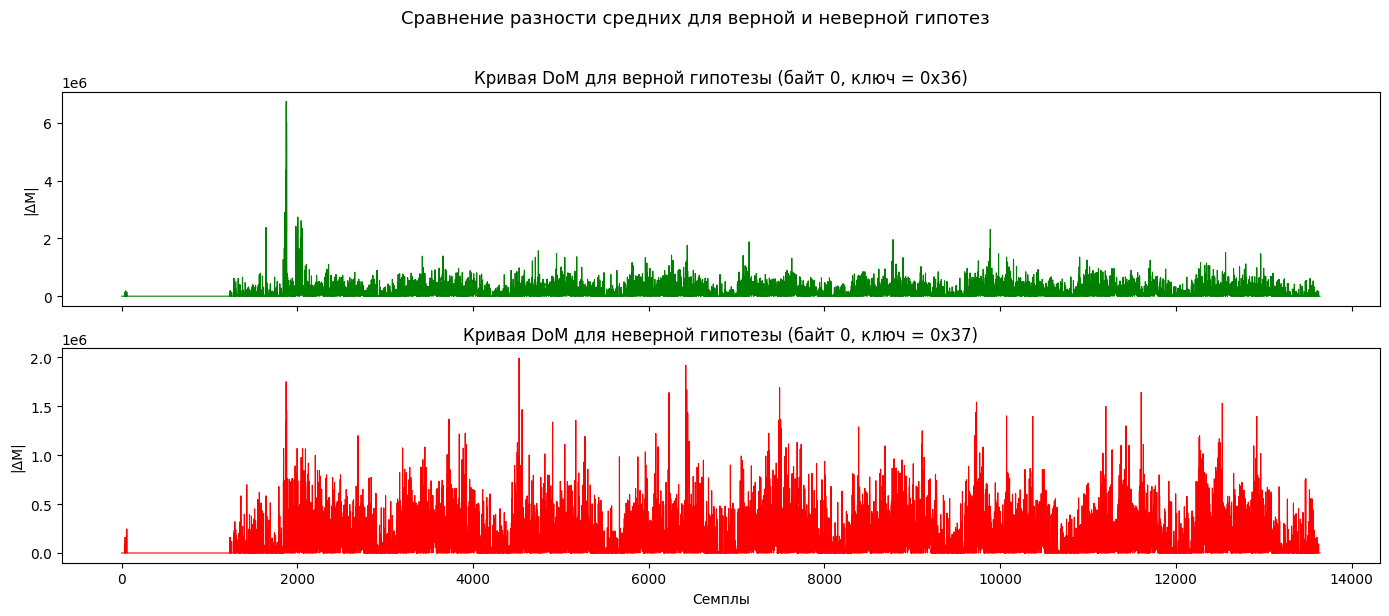

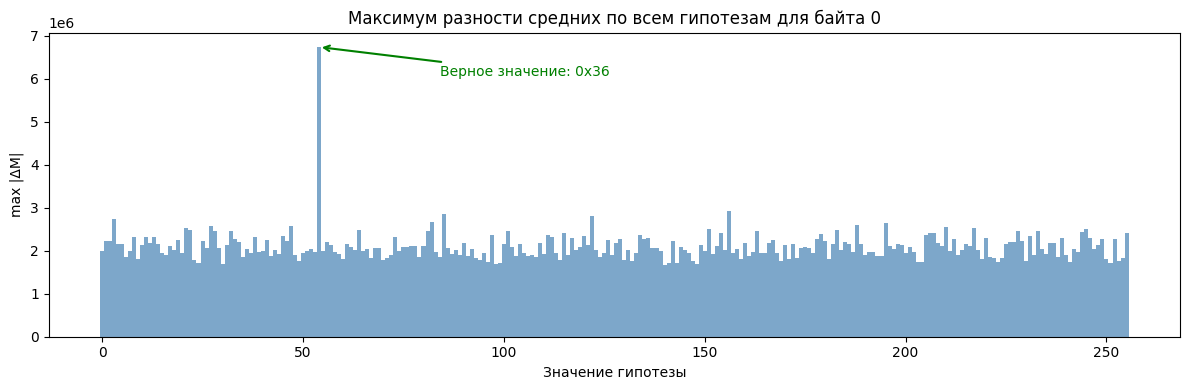

In [30]:
j       = 0
correct = KNOWN_RK10[j]
wrong   = (correct + 1) % 256

# График 1: сравнение кривых DoM
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(dom_traces[j][correct], color='green', linewidth=0.8)
axes[0].set_title(f'Кривая DoM для верной гипотезы (байт {j}, ключ = 0x{correct:02X})')
axes[0].set_ylabel('|ΔM|')

axes[1].plot(dom_traces[j][wrong], color='red', linewidth=0.8)
axes[1].set_title(f'Кривая DoM для неверной гипотезы (байт {j}, ключ = 0x{wrong:02X})')
axes[1].set_ylabel('|ΔM|')
axes[1].set_xlabel('Семплы')

fig.suptitle('Сравнение разности средних для верной и неверной гипотез', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# График 2: столбчатая диаграмма
fig2, ax2 = plt.subplots(figsize=(12, 4))
ax2.bar(range(256), deltas_dpa[j], width=1.0, color='steelblue', alpha=0.7)
ax2.annotate(
    f'Верное значение: 0x{correct:02X}',
    xy=(correct, deltas_dpa[j][correct]),
    xytext=(correct + 30, deltas_dpa[j][correct] * 0.9),
    arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
    fontsize=10, color='green'
)
ax2.set_title(f'Максимум разности средних по всем гипотезам для байта {j}')
ax2.set_xlabel('Значение гипотезы')
ax2.set_ylabel('max |ΔM|')
plt.tight_layout()
plt.show()